# Data visualization and preprocessing

In [1]:
%load_ext autoreload
%autoreload 2

In [20]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path
import sys
sys.path.append("..")

PROJECT_ROOT = Path.cwd().resolve().parent   
sys.path.insert(0, str(PROJECT_ROOT)) 


from src.datasets.build_dataset import build_cohort_b_dataset
from src.datasets.cleaning import filter_physiological_outliers, preprocess_glucose, extract_eligible_blocks
from src.visualization.eda_plots import plot_participant_boxplots, plot_participant_mean_cv, inter_individual_spread, plot_glucose_evol_day, plot_daily_mean, plot_hour_day_heatmap
from src.datasets.data_splitting import split_and_save_cohort
from src.datasets.features import build_xy_cgm_only, build_features_extra

## Data loading

CGM recordings of participants from the same cohort, with times and dates of recording

In [3]:
build_cohort_b_dataset()
DATA_DIR = Path("../../data/processed")
data = pd.read_csv(DATA_DIR / "cohort_b_glucose_data.csv")

Glucose IDs: 1119 | Metadata IDs: 1013 | Matched: 1009
Unmatched glucose IDs: 110 | Unmatched metadata IDs: 4
Cohort B participants: 864 | Rows: 1149316


### glucose audit 

To complete

## glucose distribution visualization

In [4]:
stats = inter_individual_spread(data)
print (stats)

min                 3.4150
Q1                  4.9000
median              5.2250
Q3                  5.5925
max                10.1000
IQR                 0.6925
n_participants    864.0000
Name: val, dtype: float64


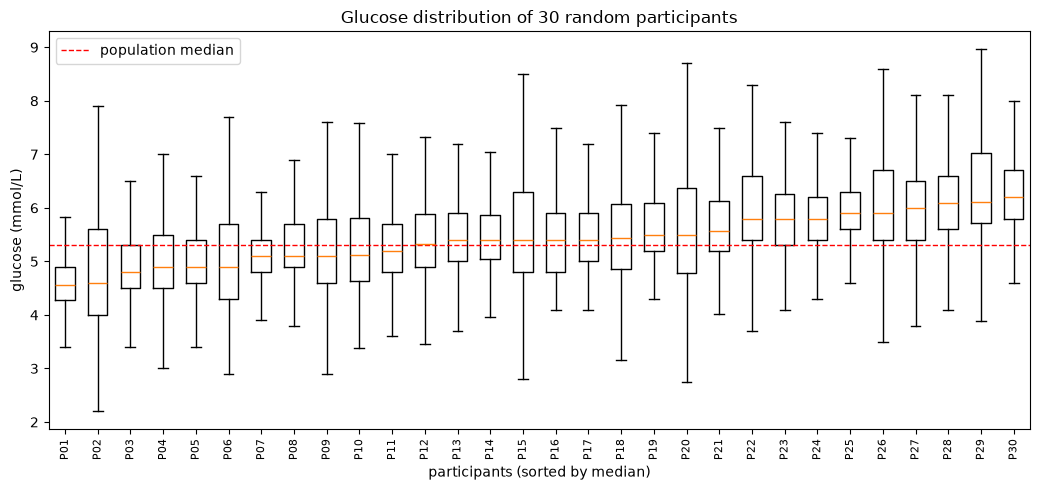

In [ ]:
plot_participant_boxplots(data)

                  user_id  n_readings       mean       std         cv
participant_rank                                                     
1                    1784         790   3.615823  0.637438  17.629129
2                      89        1334   3.643028  0.889158  24.407099
3                    1674         797   3.848306  0.830504  21.581020
4                      61        1338   3.981472  0.694077  17.432660
5                      24        1434   4.031444  0.816559  20.254750
...                   ...         ...        ...       ...        ...
860                  2091        1266   7.247709  0.886508  12.231557
861                  2029        1271   7.816129  2.200311  28.150907
862                   109        1234   7.844571  1.665520  21.231500
863                  2418        2588   8.948377  1.720146  19.222998
864                   596        3555  11.619634  6.598125  56.784274

[864 rows x 5 columns]


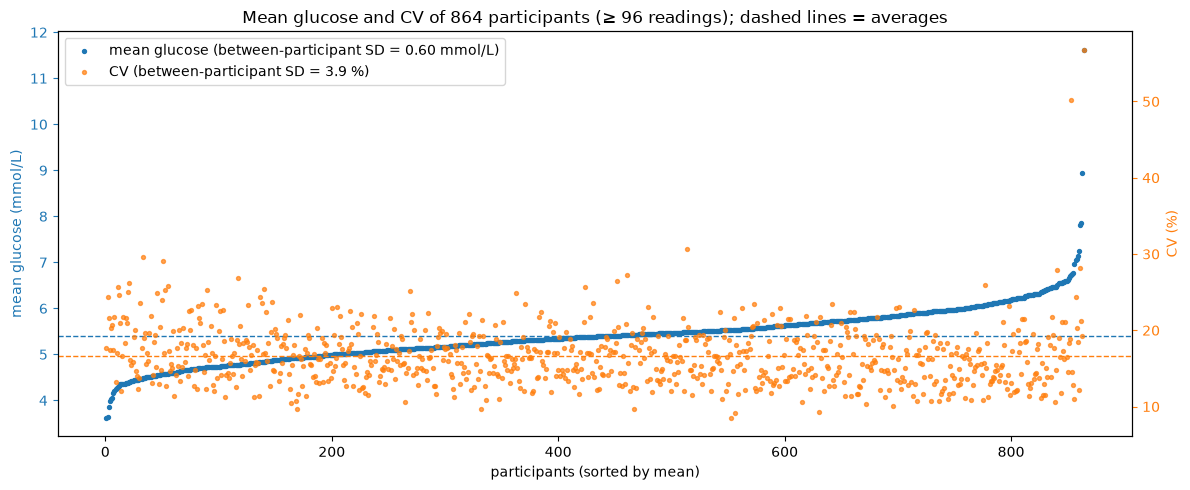

In [ ]:
stats = plot_participant_mean_cv(data)

## preprocessing

remove outliers and missing values, deal with different timestamps, and select eligible participants

In [5]:
data_good_time = preprocess_glucose("cohort_b_glucose_data.csv")
data_clean = filter_physiological_outliers(data_good_time)
data_preprocess, _, _ = extract_eligible_blocks(data_clean)

Preprocessed 1147629 bins across 864 participants -> /Users/isaureimberton/Documents/EPFL/machine_Learning/project2/data/processed/glucose_cleaned.csv
[1/3] Outlier filter [2.0, 27.8 mmol/L]: removed 3 rows (1147626 remaining)
Eligible cohort (12d consecutive >= 75%): 673 participants -> /Users/isaureimberton/Documents/EPFL/machine_Learning/project2/data/processed/glucose_eligible_12d.csv


### Glucose evolution visualization

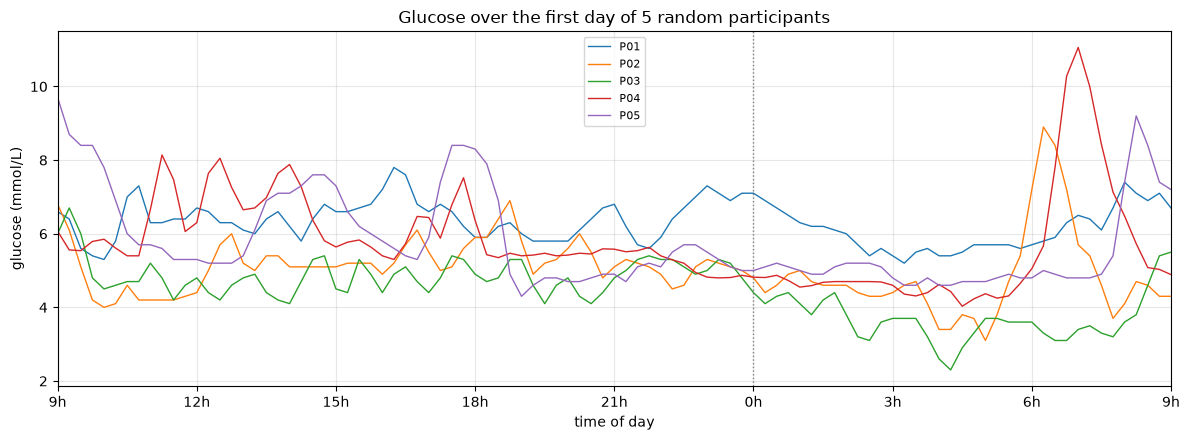

In [9]:
plot_glucose_evol_day(data_preprocess)

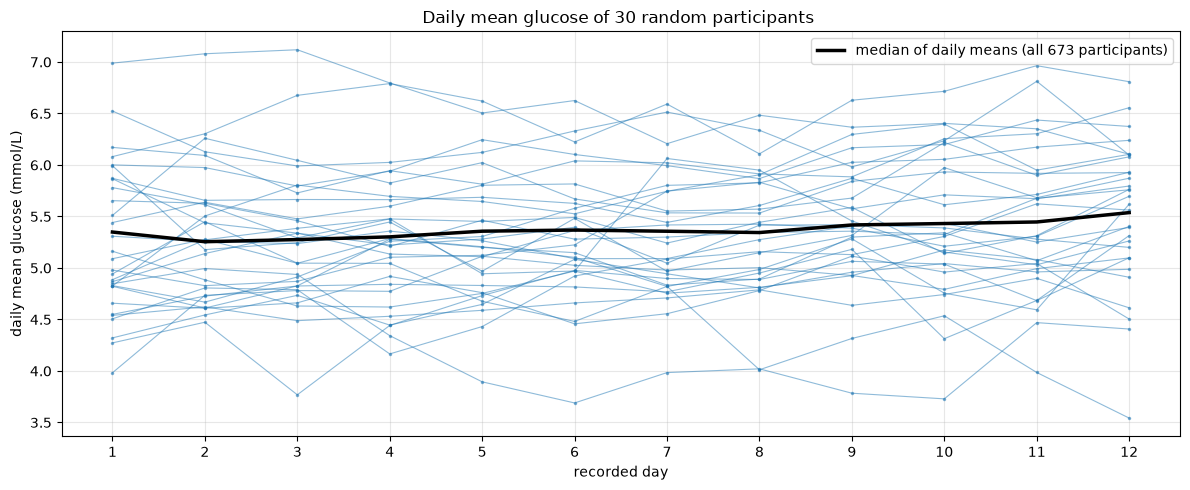

In [11]:
plot_daily_mean(data_preprocess)

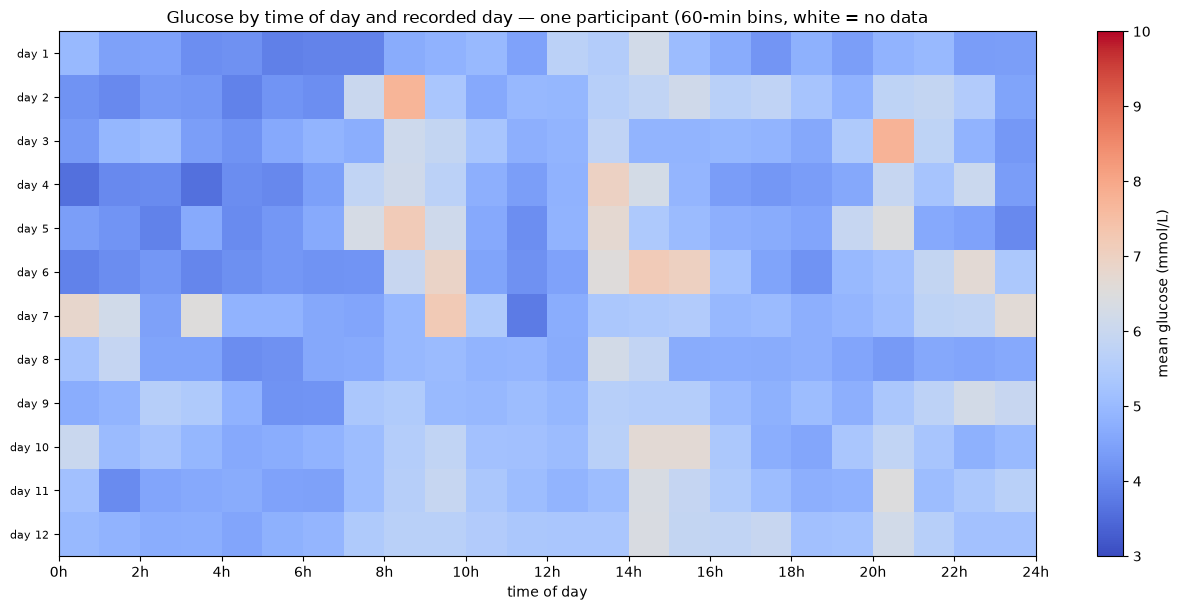

In [12]:
plot_hour_day_heatmap(data_preprocess)

## Split train and test data

In [13]:
train_data, val_data, test_data = split_and_save_cohort(data_preprocess)

Saved train_12d.csv   : 471 participants (532010 bins)
Saved val_12d.csv     : 100 participants (113163 bins)
Saved test_12d.csv    : 102 participants (115286 bins)


## Statistics on glucose data

In [17]:
X_train_data, y_train_data = build_xy_cgm_only(train_data)

In [19]:
build_features_extra(train_data)

,cgm_night_mean,cgm_day_mean,cgm_longest_gap_h
user_id,,,
5,4.794861,5.380208,0.25
9,3.827778,5.103333,0.25
21,3.925139,5.526319,0.25
22,4.921944,5.615833,0.25
24,4.091389,3.986458,0.25
...,...,...,...
2658,5.061111,6.238889,0.25
2665,5.184722,6.446853,3.00
2671,5.527778,6.809091,1.25
